# Prompt framing changes a peanut-sheller brainstorm

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/cmudrc/design-research-workshop/blob/workshop-three-agent-demos/notebooks/peanut_sheller_brainstorm.ipynb)

Run two brainstorms on the same brief. Compare which parts of the design space they explore, then choose one concept to bring into the refinement notebook.

Run each numbered section in order. A CPU runtime is enough. The workshop backend uses deterministic rules and runs without an API key.

## 1. Set up
Run the install cell once in Colab. If you installed the workshop package locally, start in the next section.

In [ ]:
# @title Install the workshop package { display-mode: "form" }
%pip -q install "design-research-workshop @ git+https://github.com/cmudrc/design-research-workshop.git@workshop-three-agent-demos"

## 2. Read the shared brief

Before running either case, predict which changes in variety you would expect from thinking through functions first. Both cases share the brief, mechanism catalog, seed, and number of ideas.

In [1]:
# @title Load the design brief { display-mode: "form" }
from dataclasses import asdict
import json
from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from design_research.problems import get_problem
from design_research_workshop import workshop_client
from design_research_workshop.peanut import (
    BRIEF, DIRECT, FUNCTION_FIRST, PROBLEM_ID, run_brainstorm,
)

count = 6  # @param {type: "integer"}
seed = 7  # @param {type: "integer"}

def show_ideas(concepts):
    table = ["| Idea | Feed | Crack | Separate |", "| ---: | --- | --- | --- |"]
    table += [
        f"| {i} | {item.feed} | {item.crack} | {item.separate} |"
        for i, item in enumerate(concepts, 1)
    ]
    display(Markdown("\n".join(table)))

print(BRIEF)
print(f"Adapted from the catalog brief ‘{get_problem(PROBLEM_ID).metadata.title}’.")

Design a non-electric tabletop peanut sheller for a small grower. Aim to keep kernels intact, use readily available materials, and make food-contact parts easy to clean.
Adapted from the catalog brief ‘Device to shell peanuts’.


## 3. Case A — Direct brainstorm

Ask for complete concepts from the brief. Look for similar cracking and separation choices across the ideas.

In [2]:
prompt_a = DIRECT
print(prompt_a)
with workshop_client() as client:
    direct = run_brainstorm(client, prompt_a, count=count, seed=seed)
show_ideas(direct)

Generate distinct complete concepts from the brief.


| Idea | Feed | Crack | Separate |
| ---: | --- | --- | --- |
| 1 | Hand-fed tray | Hinged lever press | Tilted screen |
| 2 | Gravity hopper | Hinged lever press | Tilted screen |
| 3 | Hand-fed tray | Hand-cranked rollers | Tilted screen |
| 4 | Hand-fed tray | Hinged lever press | Hand-shaken sieve |
| 5 | Indexed feed wheel | Hinged lever press | Tilted screen |
| 6 | Hand-fed tray | Sliding rub plates | Tilted screen |

## 4. Case B — Function-first brainstorm

Ask the bot to consider feeding, cracking, and separating before combining mechanisms.

In [3]:
prompt_b = FUNCTION_FIRST
print(prompt_b)
with workshop_client() as client:
    function_first = run_brainstorm(client, prompt_b, count=count, seed=seed)
show_ideas(function_first)

Think through feeding, cracking, and separating as separate functions. Combine mechanism options across the functions to create distinct concepts.


| Idea | Feed | Crack | Separate |
| ---: | --- | --- | --- |
| 1 | Hand-fed tray | Hinged lever press | Tilted screen |
| 2 | Gravity hopper | Hand-cranked rollers | Hand-shaken sieve |
| 3 | Indexed feed wheel | Sliding rub plates | Hand-cranked air separator |
| 4 | Gravity hopper | Hinged lever press | Tilted screen |
| 5 | Hand-fed tray | Hand-cranked rollers | Tilted screen |
| 6 | Hand-fed tray | Hinged lever press | Hand-shaken sieve |

## 5. Compare the two sets

Count the distinct feed, crack, and separation choices. The direct rules start with simpler combinations. The function-first rules prioritize mechanisms that have yet to appear. Coverage measures variety among those mechanism choices. You still have to decide which idea is worth developing.

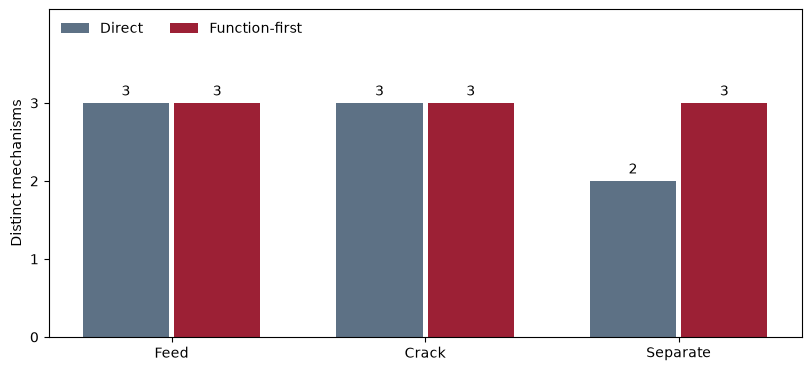

Direct — 4 distinct cracking and separation pairs
Function-first — 5 distinct cracking and separation pairs


In [4]:
axes = ("feed", "crack", "separate")
variants = {"Direct": direct, "Function-first": function_first}
coverage = {
    label: [len({getattr(concept, axis) for concept in ideas}) for axis in axes]
    for label, ideas in variants.items()
}
fig, ax = plt.subplots(figsize=(8, 3.6), layout="constrained")
for (label, values), offset, color in zip(
    coverage.items(), (-0.18, 0.18), ("#5D7185", "#9C2035"), strict=True
):
    bars = ax.bar([i + offset for i in range(3)], values, width=0.34, label=label, color=color)
    ax.bar_label(bars, padding=3)
ax.set(xticks=range(3), xticklabels=["Feed", "Crack", "Separate"],
       yticks=range(4), ylim=(0, 4.2), ylabel="Distinct mechanisms")
ax.legend(frameon=False, loc="upper left", ncols=2)
plt.show()
for label, ideas in variants.items():
    combinations = len({(idea.crack, idea.separate) for idea in ideas})
    print(f"{label} — {combinations} distinct cracking and separation pairs")

## 6. Choose a concept for refinement

Pick a case and an idea number. In Colab, download `peanut_concept.json` using **Files**, then upload it to the refinement notebook. If your two notebooks share a local working directory, the file is already there.

In [5]:
# @title Save one idea for refinement { display-mode: "form" }
case = "Function-first"  # @param ["Direct", "Function-first"]
idea_number = 2  # @param {type: "integer"}
if not 1 <= idea_number <= len(variants[case]):
    raise ValueError("Choose an idea number shown in the selected case.")
selection = variants[case][idea_number - 1]
path = Path("peanut_concept.json")
path.write_text(json.dumps(asdict(selection), indent=2), encoding="utf-8")
print(f"Saved {path.name}. {selection.feed} → {selection.crack} → {selection.separate}.")

Saved peanut_concept.json. Gravity hopper → Hand-cranked rollers → Hand-shaken sieve.


## Discuss

Which function changed most? Choose a concept for a reason that the chart cannot capture. What evidence would convince you it was worth prototyping?

[Continue to proposer–critic refinement](https://colab.research.google.com/github/cmudrc/design-research-workshop/blob/workshop-three-agent-demos/notebooks/peanut_sheller_propose_critic.ipynb).